# Loan approval prediction: a small, explainable data mining study

**Workflow:** problem → dataset → preprocessing → EDA → algorithms → evaluation → insights → conclusion.

This notebook is for a college demonstration. The learned patterns describe one small historical dataset; they are not a lending policy or a reliable production credit decision. Staff must decide applications independently. Gender is examined for descriptive fairness analysis but excluded from every model feature used for comparison and deployment.

## 1. Problem definition and dataset

The classification task is to estimate whether a historical application has `Loan_Status = Y` from its application attributes. A useful result is a repeatable comparison of common classifiers and an account of their limits, rather than a claim that an automated decision is appropriate.

The source is the [Analytics Vidhya Loan Prediction practice problem](https://datahack.analyticsvidhya.com/contest/practice-problem-loan-prediction-iii/); the included `ml/data/train.csv` is the public labeled training file mirrored at [GitHub](https://raw.githubusercontent.com/shrikant-temburwar/Loan-Prediction-Dataset/master/train.csv). It has 614 rows, 13 columns, one binary outcome, an ID, and 11 descriptive attributes. Each row is an application; monetary inputs use the dataset's units (loan amount is in thousands).

| Attribute | Meaning |
| --- | --- |
| Loan_ID | Record identifier; excluded from modeling |
| Gender | Gender category; kept for EDA/fairness audit only |
| Married, Dependents | Household information |
| Education, Self_Employed | Applicant profile categories |
| ApplicantIncome, CoapplicantIncome | Monthly incomes in dataset units |
| LoanAmount | Requested principal, in thousands |
| Loan_Amount_Term | Repayment term in months |
| Credit_History | Whether the applicant meets credit guidelines |
| Property_Area | Rural, semiurban, or urban |
| Loan_Status | Historical outcome: Y approved, N not approved |

Small sample size, historical sampling, and lack of context limit generalization. The record is not a random sample of all possible applicants.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, silhouette_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / 'ml/data/train.csv').exists() and (ROOT / 'data/train.csv').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'ml/data/train.csv'
OUT = ROOT / 'ml'
raw = pd.read_csv(DATA_PATH)
print(f'Dataset shape: {raw.shape[0]} rows × {raw.shape[1]} columns')
display(raw.head())
display(raw.dtypes.rename('dtype').to_frame())

Matplotlib created a temporary cache directory at C:\Users\SAMRID~1\AppData\Local\Temp\matplotlib-rz9z95ei because the default path (C:\Users\Samriddhi\.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Dataset shape: 614 rows × 13 columns


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,dtype
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


## 2. Preprocessing choices

The split is stratified so the roughly 69/31 approved/not-approved proportions remain similar in train and test. All imputing, encoding, and scaling live inside sklearn Pipelines and are fit on the training fold, preventing test-fold information from leaking into preprocessing.

Missing categorical values use the most frequent category because these fields are labels. Missing income and loan amount use the training median because those monetary distributions are skewed; the term and binary credit history also use median. We retain missingness summaries below so imputation is visible.

Exact duplicate rows are checked and removed before splitting. Income and loan amount have long right tails and IQR outliers; a `log1p` transform is applied to those non-negative money columns. It compresses extreme magnitudes while preserving ordering. Numeric fields are standardized because Logistic Regression and KNN are distance/scale sensitive. Categories are one-hot encoded. Loan_ID is only an identifier and Gender is deliberately omitted from model features. Feature selection is therefore a documented domain/fairness choice; no target-derived or ID-derived columns enter the classifier.

Decision Tree and Random Forest use `class_weight='balanced'`; Logistic Regression uses `class_weight='balanced'`. KNN has no built-in class-weight parameter, so its stratified evaluation uses the same split and class-sensitive precision/recall/F1 rather than pretending it supports that option.

In [2]:
print('Missing values by column:')
display(raw.isna().sum().rename('missing').to_frame())
duplicate_rows = int(raw.duplicated().sum())
print(f'Exact duplicate rows: {duplicate_rows}')
data = raw.drop_duplicates().copy()
income_outliers = {}
for column in ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']:
    values = data[column].dropna()
    q1, q3 = values.quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    income_outliers[column] = int((values > upper).sum())
print('IQR upper-tail counts (motivates log1p, not deletion):', income_outliers)
approval_rate = float((data['Loan_Status'] == 'Y').mean())
print(f'Approval rate: {approval_rate:.1%}; class counts: {data.Loan_Status.value_counts().to_dict()}')

Missing values by column:


,missing
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


Exact duplicate rows: 0
IQR upper-tail counts (motivates log1p, not deletion): {'ApplicantIncome': 50, 'CoapplicantIncome': 18, 'LoanAmount': 39}
Approval rate: 68.7%; class counts: {'Y': 422, 'N': 192}


In [3]:
preprocessing_plan = {
    'Loan_ID': 'Drop: unique identifier can memorize records and has no applicant meaning.',
    'Gender': 'Keep for EDA only; exclude from features for the fairness-conscious baseline.',
    'Married': 'Most-frequent imputation, then one-hot encoding; nominal category.',
    'Dependents': 'Most-frequent imputation, then one-hot encoding; 3+ remains a category.',
    'Education': 'Most-frequent imputation, then one-hot encoding; nominal category.',
    'Self_Employed': 'Most-frequent imputation, then one-hot encoding; nominal category.',
    'ApplicantIncome': 'Median imputation, log1p, then standard scaling; skewed non-negative money.',
    'CoapplicantIncome': 'Median imputation, log1p, then standard scaling; skewed and often zero.',
    'LoanAmount': 'Median imputation, log1p, then standard scaling; skewed and measured in thousands.',
    'Loan_Amount_Term': 'Median imputation and standard scaling; numeric months.',
    'Credit_History': 'Median imputation and standard scaling; binary guideline indicator.',
    'Property_Area': 'Most-frequent imputation, then one-hot encoding; nominal category.',
    'Loan_Status': 'Target only: map N to 0 and Y to 1; never included as a feature.'
}
display(pd.DataFrame([{'column': column, 'preprocessing_reason': reason}
                      for column, reason in preprocessing_plan.items()]))

,column,preprocessing_reason
0,Loan_ID,Drop: unique identifier can memorize records a...
1,Gender,Keep for EDA only; exclude from features for t...
2,Married,"Most-frequent imputation, then one-hot encodin..."
3,Dependents,"Most-frequent imputation, then one-hot encodin..."
4,Education,"Most-frequent imputation, then one-hot encodin..."
5,Self_Employed,"Most-frequent imputation, then one-hot encodin..."
6,ApplicantIncome,"Median imputation, log1p, then standard scalin..."
7,CoapplicantIncome,"Median imputation, log1p, then standard scalin..."
8,LoanAmount,"Median imputation, log1p, then standard scalin..."
9,Loan_Amount_Term,Median imputation and standard scaling; numeri...


## 3. Exploratory data analysis

These charts describe the full labeled dataset and are not used to tune the held-out evaluation. Gender appears only in this descriptive section. The numeric correlation matrix uses numeric columns only; its association values are descriptive, not causal.

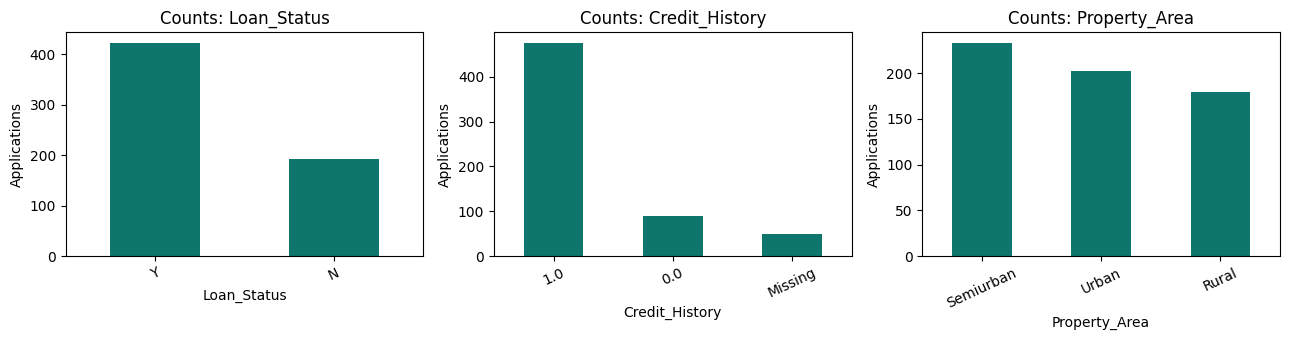

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ['Loan_Status', 'Credit_History', 'Property_Area']):
    data[column].fillna('Missing').value_counts().plot(kind='bar', ax=ax, color='#0f766e')
    ax.set_title(f'Counts: {column}'); ax.set_ylabel('Applications'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

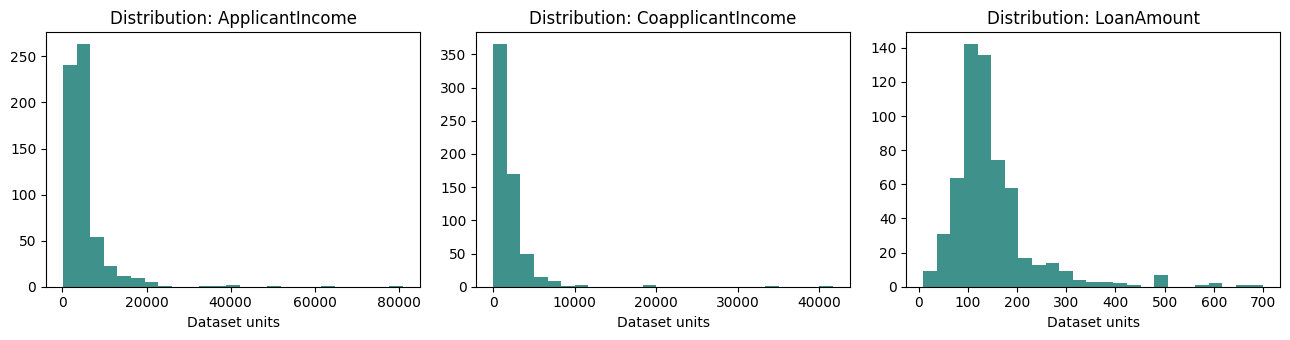

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']):
    ax.hist(data[column].dropna(), bins=25, color='#0f766e', alpha=.8)
    ax.set_title(f'Distribution: {column}'); ax.set_xlabel('Dataset units')
plt.tight_layout(); plt.show()

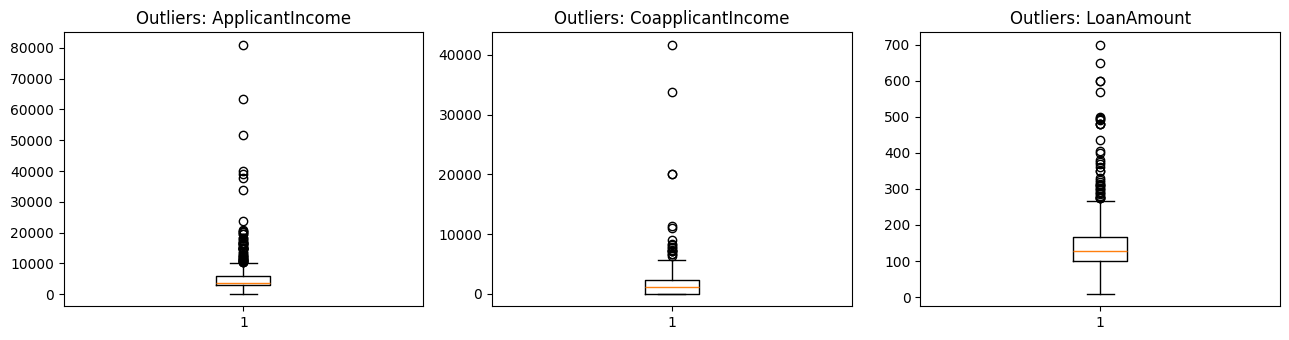

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, column in zip(axes, ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']):
    ax.boxplot(data[column].dropna(), vert=True); ax.set_title(f'Outliers: {column}')
plt.tight_layout(); plt.show()

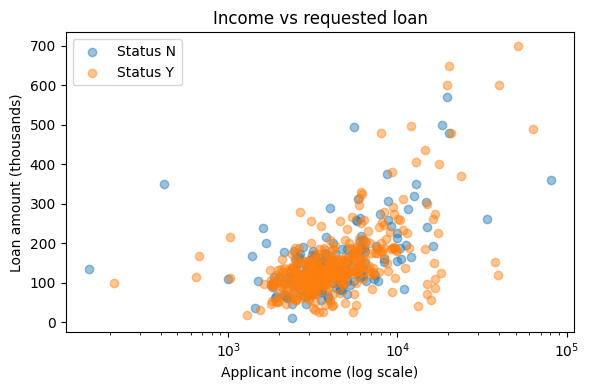

In [7]:
plt.figure(figsize=(6, 4))
for label, group in data.groupby('Loan_Status'):
    plt.scatter(group['ApplicantIncome'], group['LoanAmount'], alpha=.45, label=f'Status {label}')
plt.xscale('log'); plt.xlabel('Applicant income (log scale)'); plt.ylabel('Loan amount (thousands)')
plt.title('Income vs requested loan'); plt.legend(); plt.tight_layout(); plt.show()

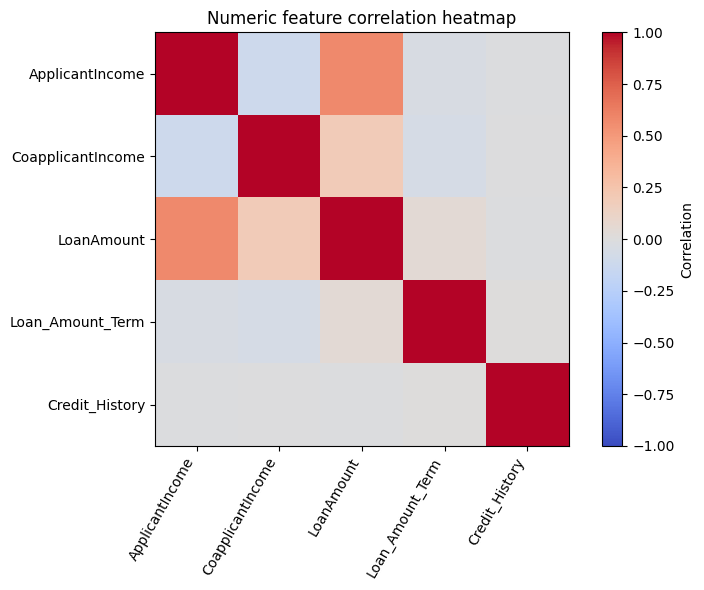

In [8]:
numeric_eda = data.select_dtypes(include=np.number)
plt.figure(figsize=(8, 6)); plt.imshow(numeric_eda.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(numeric_eda.columns)), numeric_eda.columns, rotation=60, ha='right')
plt.yticks(range(len(numeric_eda.columns)), numeric_eda.columns); plt.colorbar(label='Correlation')
plt.title('Numeric feature correlation heatmap'); plt.tight_layout(); plt.show()

In [9]:
gender_approval = data.groupby('Gender', dropna=False)['Loan_Status'].apply(lambda x: (x == 'Y').mean())
gender_numeric = data['Gender'].map({'Female': 0, 'Male': 1})
target_numeric = data['Loan_Status'].map({'N': 0, 'Y': 1})
gender_correlation = float(gender_numeric.corr(target_numeric))
print('Approval rate by recorded gender (descriptive only):')
display(gender_approval.rename('approval_rate').to_frame())
print(f'Gender/outcome Pearson correlation after Male=1, Female=0 encoding: {gender_correlation:.3f}')

Approval rate by recorded gender (descriptive only):


,approval_rate
Gender,
Female,0.669643
Male,0.693252
NaN,0.615385


Gender/outcome Pearson correlation after Male=1, Female=0 encoding: 0.020


## 4. Algorithms and evaluation plan

One fixed 70/30 stratified holdout split is shared by Decision Tree, Logistic Regression, KNN, and Random Forest. The same feature set, preprocessing pipeline, and random state are used. Five-fold stratified CV on the training portion gives a second view of F1 variability. Accuracy is included but is not sufficient under class imbalance; precision and recall show the error trade-off, F1 combines them, and ROC-AUC evaluates ranking across thresholds. Confusion matrices use `[[TN, FP], [FN, TP]]` with class order not-approved then approved.

Random Forest is the main deployable model because it handles nonlinear category interactions and supplies feature importances for a classroom explanation. These importances are associations in this fitted model, not causal effects.

In [10]:
TARGET = 'Loan_Status'
DROP = ['Loan_ID', 'Gender', TARGET]
FEATURES = [column for column in data.columns if column not in DROP]
CATEGORICAL = ['Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
LOG_NUMERIC = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
SCALED_NUMERIC = ['Loan_Amount_Term', 'Credit_History']

def make_preprocessor(include_gender=False):
    categorical = CATEGORICAL + (['Gender'] if include_gender else [])
    log_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler())
    ])
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ])
    category_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('money_log', log_pipeline, LOG_NUMERIC),
        ('numeric', numeric_pipeline, SCALED_NUMERIC),
        ('category', category_pipeline, categorical)
    ], remainder='drop')

X = data[FEATURES].copy()
y = data[TARGET].map({'N': 0, 'Y': 1}).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.30, stratify=y, random_state=RANDOM_STATE
)
print(f'Train rows: {len(X_train)}; test rows: {len(X_test)}')
print('Train approval rate:', round(float(y_train.mean()), 3), '| test approval rate:', round(float(y_test.mean()), 3))

models = {
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE, min_samples_leaf=5),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=11, weights='distance'),
    'Random Forest': RandomForestClassifier(n_estimators=150, class_weight='balanced', min_samples_leaf=2,
                                             random_state=RANDOM_STATE, n_jobs=1)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
comparison = []
fitted_models = {}
confusions = {}
for name, estimator in models.items():
    pipeline = Pipeline([('preprocessor', make_preprocessor()), ('classifier', clone(estimator))])
    pipeline.fit(X_train, y_train)
    prediction = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]
    cv_f1 = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='f1', n_jobs=1)
    matrix = confusion_matrix(y_test, prediction, labels=[0, 1])
    confusions[name] = matrix
    comparison.append({
        'model': name,
        'accuracy': float(accuracy_score(y_test, prediction)),
        'precision': float(precision_score(y_test, prediction, zero_division=0)),
        'recall': float(recall_score(y_test, prediction, zero_division=0)),
        'f1': float(f1_score(y_test, prediction, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_test, probability)),
        'cv_f1_mean': float(cv_f1.mean()),
        'cv_f1_std': float(cv_f1.std())
    })
    fitted_models[name] = pipeline
comparison_df = pd.DataFrame(comparison).sort_values('f1', ascending=False)
display(comparison_df.round(3))

Train rows: 429; test rows: 185
Train approval rate: 0.688 | test approval rate: 0.686


C:\Users\Samriddhi\Aditya\loanDolphin\ml\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Samriddhi\Aditya\loanDolphin\ml\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Samriddhi\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Samriddhi\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:

,model,accuracy,precision,recall,f1,roc_auc,cv_f1_mean,cv_f1_std
2,KNN,0.849,0.837,0.969,0.898,0.802,0.851,0.008
3,Random Forest,0.805,0.832,0.898,0.864,0.803,0.831,0.027
1,Logistic Regression,0.773,0.857,0.803,0.829,0.822,0.767,0.029
0,Decision Tree,0.676,0.845,0.646,0.732,0.760,0.694,0.054


In [11]:
main_pipeline = fitted_models['Random Forest']
main_prediction = main_pipeline.predict(X_test)
main_probability = main_pipeline.predict_proba(X_test)[:, 1]
main_cm = confusion_matrix(y_test, main_prediction, labels=[0, 1])
print('Random Forest confusion matrix [[TN, FP], [FN, TP]]:')
display(pd.DataFrame(main_cm, index=['Actual N', 'Actual Y'], columns=['Predicted N', 'Predicted Y']))
print(f'Random Forest ROC-AUC: {roc_auc_score(y_test, main_probability):.3f}')

Random Forest confusion matrix [[TN, FP], [FN, TP]]:


,Predicted N,Predicted Y
Actual N,35,23
Actual Y,13,114


Random Forest ROC-AUC: 0.803


,source_feature,importance
2,Credit,0.2336
0,ApplicantIncome,0.1916
6,LoanAmount,0.1765
1,CoapplicantIncome,0.1188
3,Dependents,0.0743
8,Property,0.0720
7,Married,0.0418
4,Education,0.0359
5,Loan,0.0321
9,Self,0.0234


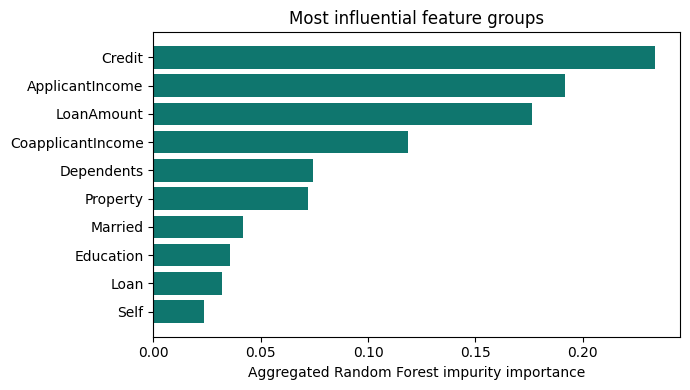

In [12]:
rf = main_pipeline.named_steps['classifier']
names = main_pipeline.named_steps['preprocessor'].get_feature_names_out()
importance = pd.DataFrame({'transformed_feature': names, 'importance': rf.feature_importances_})
importance['source_feature'] = importance.transformed_feature.str.split('__').str[-1].str.split('_').str[0]
importance_summary = (importance.groupby('source_feature', as_index=False).importance.sum()
                      .sort_values('importance', ascending=False))
display(importance_summary.head(10).round(4))
top = importance_summary.head(10).sort_values('importance')
plt.figure(figsize=(7, 4)); plt.barh(top.source_feature, top.importance, color='#0f766e')
plt.xlabel('Aggregated Random Forest impurity importance'); plt.title('Most influential feature groups')
plt.tight_layout(); plt.show()

## 5. Gender exclusion check and optional applicant segmentation

To show the effect of the fairness feature choice once, fit the same Random Forest with Gender added to the training features and compare its held-out metrics with the gender-excluded Random Forest above. This is an audit comparison only; the model artifact remains gender-free. A small difference does not establish fairness, and a large one would motivate deeper subgroup error analysis.

K-Means is an optional unsupervised second technique. Three segments are chosen for a simple demonstration, not because three is known to be optimal. Silhouette score summarizes separation in the transformed feature space; profiles are descriptive and are not approval recommendations.

In [13]:
X_with_gender = data[FEATURES + ['Gender']].copy()
Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_with_gender, y, test_size=.30, stratify=y, random_state=RANDOM_STATE
)
gender_rf = Pipeline([
    ('preprocessor', make_preprocessor(include_gender=True)),
    ('classifier', RandomForestClassifier(n_estimators=150, class_weight='balanced', min_samples_leaf=2,
                                          random_state=RANDOM_STATE, n_jobs=1))
])
gender_rf.fit(Xg_train, yg_train)
gender_prob = gender_rf.predict_proba(Xg_test)[:, 1]
gender_pred = gender_rf.predict(Xg_test)
gender_effect = {
    'without_gender_accuracy': float(accuracy_score(y_test, main_prediction)),
    'with_gender_accuracy': float(accuracy_score(yg_test, gender_pred)),
    'without_gender_f1': float(f1_score(y_test, main_prediction, zero_division=0)),
    'with_gender_f1': float(f1_score(yg_test, gender_pred, zero_division=0)),
    'without_gender_roc_auc': float(roc_auc_score(y_test, main_probability)),
    'with_gender_roc_auc': float(roc_auc_score(yg_test, gender_prob))
}
display(pd.DataFrame([gender_effect]).round(3))

preprocessed = make_preprocessor().fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=20)
clusters = kmeans.fit_predict(preprocessed)
silhouette = float(silhouette_score(preprocessed, clusters))
cluster_profiles = data.assign(cluster=clusters).groupby('cluster').agg(
    applicants=('Loan_ID', 'count'), approval_rate=('Loan_Status', lambda s: float((s == 'Y').mean())),
    median_income=('ApplicantIncome', 'median'), median_loan=('LoanAmount', 'median'),
    credit_history_rate=('Credit_History', 'mean')
).reset_index()
display(cluster_profiles.round(3))
print(f'K-Means silhouette score (k=3): {silhouette:.3f}')

,without_gender_accuracy,with_gender_accuracy,without_gender_f1,with_gender_f1,without_gender_roc_auc,with_gender_roc_auc
0,0.805,0.795,0.864,0.856,0.803,0.782


,cluster,applicants,approval_rate,median_income,median_loan,credit_history_rate
0,0,292,0.822,3279.5,131.0,1.0
1,1,233,0.751,4758.0,120.0,1.0
2,2,89,0.079,3547.0,125.0,0.0


K-Means silhouette score (k=3): 0.207


## 6. Results, interpretation, and limitations

The comparison table should be read across all metrics. Recall answers how many historically approved applications were found; precision answers how many predicted approvals were approved in this dataset. A false positive and a false negative have different consequences in lending, so a threshold would require a policy decision and stakeholder review rather than an automatic default.

Approval rates by credit history, property area, and education give context to the fitted model. They are observational rates, not effects. Correlated attributes, missing records, selection into historical applications, a small sample, and unknown collection practices can all distort the apparent relationships. The gender comparison is included as one diagnostic only; fairness requires subgroup outcome/error analysis and a justified review process.

In [14]:
def approval_rate_by(column):
    return {str(key): float(value) for key, value in
            data.groupby(column, dropna=False)['Loan_Status'].apply(lambda values: (values == 'Y').mean()).items()}

eda_summary = {
    'approval_rate_by_credit_history': approval_rate_by('Credit_History'),
    'approval_rate_by_property_area': approval_rate_by('Property_Area'),
    'approval_rate_by_education': approval_rate_by('Education'),
    'approval_rate_by_gender_eda_only': {str(k): float(v) for k, v in gender_approval.items()},
    'gender_outcome_correlation_eda_only': gender_correlation,
    'overall_approval_rate': approval_rate,
    'class_counts': {str(k): int(v) for k, v in data.Loan_Status.value_counts().items()},
    'missing_by_column': {str(k): int(v) for k, v in raw.isna().sum().items()},
    'duplicate_rows_removed': duplicate_rows,
    'iqr_upper_outliers': income_outliers
}
print('EDA summary values:')
display(pd.DataFrame([
    {'feature': key, 'approval_rates': value}
    for key, value in eda_summary.items() if key.startswith('approval_rate_by_')
]))
print('Gender comparison:', gender_effect)
print('Random Forest test metrics:', comparison_df.set_index('model').loc['Random Forest'].to_dict())

EDA summary values:


,feature,approval_rates
0,approval_rate_by_credit_history,"{'0.0': 0.07865168539325842, '1.0': 0.79578947..."
1,approval_rate_by_property_area,"{'Rural': 0.6145251396648045, 'Semiurban': 0.7..."
2,approval_rate_by_education,"{'Graduate': 0.7083333333333334, 'Not Graduate..."
3,approval_rate_by_gender_eda_only,"{'Female': 0.6696428571428571, 'Male': 0.69325..."


Gender comparison: {'without_gender_accuracy': 0.8054054054054054, 'with_gender_accuracy': 0.7945945945945946, 'without_gender_f1': 0.8636363636363636, 'with_gender_f1': 0.8560606060606061, 'without_gender_roc_auc': 0.8034211240836274, 'with_gender_roc_auc': 0.7821069780070594}
Random Forest test metrics: {'accuracy': 0.8054054054054054, 'precision': 0.8321167883211679, 'recall': 0.8976377952755905, 'f1': 0.8636363636363636, 'roc_auc': 0.8034211240836274, 'cv_f1_mean': 0.83093413431247, 'cv_f1_std': 0.026678921676278566}


In [15]:
leader = comparison_df.iloc[0]
top_groups = ', '.join(importance_summary.head(3).source_feature.tolist())
print(f"On this fixed holdout, {leader.model} has the highest F1 ({leader.f1:.3f}); Random Forest is retained as the main model for its tree ensemble and feature-group importance summary.")
print(f"The Random Forest identifies {top_groups} as its highest-importance groups; these describe learned associations, not causal drivers.")
print(f"Credit-history approval rates in this sample: {eda_summary['approval_rate_by_credit_history']}.")
print('Real-world usefulness: the workflow demonstrates how historical application patterns can support staff review and discussion, but sample size, age, representativeness, calibration, and fairness checks prevent using these outputs as automatic decisions.')

On this fixed holdout, KNN has the highest F1 (0.898); Random Forest is retained as the main model for its tree ensemble and feature-group importance summary.
The Random Forest identifies Credit, ApplicantIncome, LoanAmount as its highest-importance groups; these describe learned associations, not causal drivers.
Credit-history approval rates in this sample: {'0.0': 0.07865168539325842, '1.0': 0.7957894736842105, 'nan': 0.74}.
Real-world usefulness: the workflow demonstrates how historical application patterns can support staff review and discussion, but sample size, age, representativeness, calibration, and fairness checks prevent using these outputs as automatic decisions.


## 7. Final artifacts and conclusion

For the demo service, refit the gender-free Random Forest pipeline on all labeled rows after the holdout evaluation. The held-out records remain separately saved in `test_sample.csv` for repeatable demo seeding; they were not used to fit the evaluated pipeline until this final artifact fit. The pipeline includes imputation, log transforms, scaling, encoding, and the classifier, so inference needs no separate encoder.

The study compared four classifiers on the same split. The best classroom model is not automatically a useful lending model: its actual value depends on representative data, calibrated probabilities, subgroup evaluation, transparent policy, privacy controls, and human review. Future work should use a larger current dataset, assess calibration and subgroup error rates, document data provenance, and validate any threshold with domain experts.

In [16]:
rf_row = comparison_df.set_index('model').loc['Random Forest']
rf_importances = {str(row.source_feature): float(row.importance) for row in importance_summary.itertuples()}
metrics = {
    'model_name': 'Random Forest',
    'model_version': 'rf-ca2-v1',
    'dataset': 'Analytics Vidhya Loan Prediction train.csv',
    'n_rows': int(len(data)),
    'n_train': int(len(X_train)),
    'n_test': int(len(X_test)),
    'accuracy': float(rf_row.accuracy),
    'precision': float(rf_row.precision),
    'recall': float(rf_row.recall),
    'f1': float(rf_row.f1),
    'roc_auc': float(rf_row.roc_auc),
    'cv_f1_mean': float(rf_row.cv_f1_mean),
    'cv_f1_std': float(rf_row.cv_f1_std),
    'confusion_matrix': main_cm.astype(int).tolist(),
    'confusion_matrix_labels': ['Not approved', 'Approved'],
    'model_comparison': comparison_df.to_dict(orient='records'),
    'feature_importances': rf_importances,
    'eda': eda_summary,
    'gender_included_comparison': gender_effect,
    'cluster': {
        'silhouette_score': silhouette,
        'profiles': json.loads(cluster_profiles.to_json(orient='records'))
    }
}
final_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', RandomForestClassifier(n_estimators=150, class_weight='balanced', min_samples_leaf=2,
                                          random_state=RANDOM_STATE, n_jobs=1))
])
final_model.fit(X, y)
joblib.dump(final_model, OUT / 'model.joblib')
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2, allow_nan=False), encoding='utf-8')
test_rows = raw.loc[X_test.index].copy()
test_rows.to_csv(OUT / 'test_sample.csv', index=False)
print('Saved:', OUT / 'model.joblib', OUT / 'metrics.json', OUT / 'test_sample.csv')
display(pd.DataFrame([metrics]).drop(columns=['model_comparison', 'feature_importances', 'eda', 'cluster']).T)

Saved: C:\Users\Samriddhi\Aditya\loanDolphin\ml\model.joblib C:\Users\Samriddhi\Aditya\loanDolphin\ml\metrics.json C:\Users\Samriddhi\Aditya\loanDolphin\ml\test_sample.csv


,0
model_name,Random Forest
model_version,rf-ca2-v1
dataset,Analytics Vidhya Loan Prediction train.csv
n_rows,614
n_train,429
n_test,185
accuracy,0.805405
precision,0.832117
recall,0.897638
f1,0.863636
